# Clustering emotional journeys (CMU-MOSEI)

**Goal.** Each cleaned video is one person's emotional path across the clip. There are 1,279 cleaned videos. We group those paths into a few recurring **shapes** (archetypes), so each shape can later be written as a short behavioral-journey instruction and added on top of a persona.

**What we cluster, and the key idea.** We cluster on the **shape of the sentiment arc over time** (how the mood moves), *not* on whether the person is positive or negative overall. A first attempt that kept the overall level just split the data into 'positive people' vs 'negative people' (k=2), which says nothing about journeys. On this data the overall level carries more variance than the movement, so unless we remove it, k-means keeps rediscovering it. We therefore mean-center each arc (subtract its own average) before clustering, and keep the average as a *label* for describing each cluster.

**Outputs.** A small set of trajectory archetypes (rising, falling, dips-in-middle, peaks-in-middle, flat), each with an average-arc plot, a one-sentence journey description, example videos with transcripts, and exported CSVs.

## 1. Setup

Input is the small combined table `segment_transcripts_with_labels.csv` (~4MB) from **Northwestern x Accenture -> Dataset -> CMU-MOSEI**. One row per labeled utterance with its 7 affect scores and transcript. Run in Colab (mount Drive) or locally (point `CSV_PATH` at a local copy). No large files are needed.

In [1]:
try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False
print('Colab:', IN_COLAB)

Mounted at /content/drive
Colab: True


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42

CSV_CANDIDATES = [
    '/content/drive/MyDrive/Northwestern x Accenture/Dataset/CMU-MOSEI/segment_transcripts_with_labels.csv',
    '/content/drive/My Drive/Northwestern x Accenture/Dataset/CMU-MOSEI/segment_transcripts_with_labels.csv',
    './segment_transcripts_with_labels.csv',
    '../data/segment_transcripts_with_labels.csv',
    './data/segment_transcripts_with_labels.csv',
]
CSV_PATH = next((p for p in CSV_CANDIDATES if os.path.exists(p)), None)
assert CSV_PATH, 'Could not find segment_transcripts_with_labels.csv. Set CSV_PATH manually.'

OUTPUT_DIR = '/content/drive/MyDrive/Northwestern x Accenture/Dataset/CMU-MOSEI/clustering_outputs' if IN_COLAB else './clustering_outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print('Reading:', CSV_PATH)
print('Writing outputs to:', OUTPUT_DIR)

Reading: /content/drive/MyDrive/Northwestern x Accenture/Dataset/CMU-MOSEI/segment_transcripts_with_labels.csv
Writing outputs to: /content/drive/MyDrive/Northwestern x Accenture/Dataset/CMU-MOSEI/clustering_outputs


In [3]:
EMOTIONS = ['happy', 'sad', 'anger', 'surprise', 'disgust', 'fear']
df = pd.read_csv(CSV_PATH)
print('rows (utterances):', len(df))
print('videos:', df['video_id'].nunique())
df.head()

rows (utterances): 23259
videos: 3293


,video_id,segment_index,interval_start,interval_end,transcript,sentiment,happy,sad,anger,surprise,disgust,fear
0,--qXJuDtHPw,0,23.199,30.325,writer i see that a writer is somebody who has...,1.000000,0.666667,0.000000,0.0,0.0,0.0,0.000000
1,-3g5yACwYnA,0,82.753,100.555,key is part of the people that we use to solve...,1.000000,0.666667,0.666667,0.0,0.0,0.0,0.666667
2,-3g5yACwYnA,1,119.919,125.299,that we do they've been able to find solutions...,0.666667,0.000000,0.000000,0.0,0.0,0.0,0.000000
3,-3g5yACwYnA,2,4.840,14.052,operations key polymer brings a technical aspe...,0.000000,0.666667,0.666667,0.0,0.0,0.0,0.333333
4,-3g5yACwYnA,3,13.211,27.521,internally we're a huge user of adhesives for ...,0.000000,0.333333,0.333333,0.0,0.0,0.0,0.000000


## 2. Reproduce the clean set (1,279 videos)

Same screens as the cleaning notebook: at least 3 utterances, no unlabeled gap over 10s, labels covering at least 80% of the span, and 3 manual exclusions. The waterfall should end at **1,279**.

In [4]:
EPS = 1e-6
MIN_UTTERANCES = 3
MAX_UNLABELED_GAP_SECONDS = 10.0
MIN_LABEL_COVERAGE = 0.80
MANUAL_REVIEW_EXCLUSIONS = {
    '34-ogj6rh6w': 'explicit exchange involving multiple named people',
    'luQfWSfb1s0': 'explicit colleague handover within source',
    'kh6eynD9OIk': 'possible multiple accounts/speakers; unresolved from transcript alone',
}

def union_length(intervals):
    iv = sorted(intervals)
    total = 0.0
    cs, ce = iv[0]
    for s, e in iv[1:]:
        if s > ce:
            total += ce - cs
            cs, ce = s, e
        else:
            ce = max(ce, e)
    total += ce - cs
    return total

stats = []
for vid, g in df.groupby('video_id'):
    iv = list(zip(g['interval_start'].astype(float), g['interval_end'].astype(float)))
    ivs = sorted(iv)
    span = max(e for _, e in ivs) - min(s for s, _ in ivs)
    gaps = [ivs[i + 1][0] - ivs[i][1] for i in range(len(ivs) - 1)]
    max_gap = max(gaps + [0.0])
    coverage = union_length(ivs) / span if span > 0 else 0.0
    stats.append({'video_id': vid, 'n_utterances': len(iv), 'max_gap': max_gap, 'coverage': coverage})
stats = pd.DataFrame(stats)
stats['pass_len'] = stats['n_utterances'] >= MIN_UTTERANCES
stats['pass_gap'] = stats['max_gap'] <= MAX_UNLABELED_GAP_SECONDS + EPS
stats['pass_cov'] = stats['coverage'] >= MIN_LABEL_COVERAGE - EPS
stats['pass_manual'] = ~stats['video_id'].isin(MANUAL_REVIEW_EXCLUSIONS)
n0 = len(stats)
n1 = int((~stats['pass_len']).sum())
n2 = int((stats['pass_len'] & ~stats['pass_gap']).sum())
n3 = int((stats['pass_len'] & stats['pass_gap'] & ~stats['pass_cov']).sum())
n4 = int((stats['pass_len'] & stats['pass_gap'] & stats['pass_cov'] & ~stats['pass_manual']).sum())
retained_ids = set(stats[stats[['pass_len','pass_gap','pass_cov','pass_manual']].all(axis=1)]['video_id'])
print(f'start videos          : {n0}')
print(f'removed <3 utterances : {n1}  -> {n0-n1}')
print(f'removed gap>10s       : {n2}  -> {n0-n1-n2}')
print(f'removed coverage<80%  : {n3}  -> {n0-n1-n2-n3}')
print(f'removed manual        : {n4}  -> {n0-n1-n2-n3-n4}')
print(f'RETAINED              : {len(retained_ids)}')
assert len(retained_ids) == 1279, 'Screen did not reproduce 1,279; check the input CSV version.'

start videos          : 3293
removed <3 utterances : 816  -> 2477
removed gap>10s       : 1072  -> 1405
removed coverage<80%  : 123  -> 1282
removed manual        : 3  -> 1279
RETAINED              : 1279


## 3. Build one journey per video

Sort each video's utterances in time and read off the sentiment at each step. That ordered list is the emotional path. We also keep emotion presence for describing clusters later.

In [5]:
clean = df[df['video_id'].isin(retained_ids)].copy()
clean['mid'] = (clean['interval_start'].astype(float) + clean['interval_end'].astype(float)) / 2.0
clean = clean.sort_values(['video_id', 'mid']).reset_index(drop=True)
journeys = {}
for vid, g in clean.groupby('video_id'):
    t = g['mid'].to_numpy(dtype=float)
    t_norm = (t - t.min()) / (t.max() - t.min()) if t.max() > t.min() else np.linspace(0, 1, len(t))
    journeys[vid] = {
        'sentiment': g['sentiment'].to_numpy(dtype=float),
        't_norm': t_norm,
        'emotions': g[EMOTIONS].to_numpy(dtype=float),
        'transcript': g['transcript'].fillna('').tolist(),
        'n': len(g),
    }
print('journeys built:', len(journeys))

journeys built: 1279


## 4. Turn each journey into a comparable **shape**

Two steps:

1. Stretch every path onto the same 12-point timeline (0 = start, 1 = end) by interpolation, so a 4-utterance and a 40-utterance arc are comparable.
2. **Mean-center** each arc (subtract its own average). This is what makes the clustering about *movement* instead of *overall positivity*. The average level is kept separately as a descriptor.

Shape features: the mean-centered 12-point curve + trend slope + curvature (peak vs dip in the middle) + start-to-end change + volatility + where the high and low points fall. Emotions are **not** used for clustering (they are sparse in MOSEI); they only label clusters afterwards.

In [6]:
L = 12
grid = np.linspace(0, 1, L)

def resample(t_norm, values, grid):
    order = np.argsort(t_norm)
    t_sorted = t_norm[order]
    v_sorted = np.asarray(values)[order]
    uniq, idx = np.unique(t_sorted, return_inverse=True)
    if len(uniq) < len(t_sorted):
        v_avg = np.array([v_sorted[idx == k].mean() for k in range(len(uniq))])
    else:
        v_avg = v_sorted
    if len(uniq) == 1:
        return np.full(len(grid), v_avg[0])
    return np.interp(grid, uniq, v_avg)

vids = list(journeys)
arcs = np.vstack([resample(journeys[v]['t_norm'], journeys[v]['sentiment'], grid) for v in vids])
emotion_means = np.vstack([journeys[v]['emotions'].mean(axis=0) for v in vids])
emotion_base = emotion_means.mean(axis=0)  # dataset-wide average presence of each emotion

mean_level = arcs.mean(axis=1)
start_third = arcs[:, :L // 3].mean(axis=1)
end_third = arcs[:, -L // 3:].mean(axis=1)
mid_third = arcs[:, L // 3:2 * L // 3].mean(axis=1)

shape = arcs - mean_level[:, None]
slope = np.array([np.polyfit(grid, a, 1)[0] for a in arcs])
curvature = mid_third - (start_third + end_third) / 2
delta = end_third - start_third
volatility = np.abs(np.diff(arcs, axis=1)).mean(axis=1)
peak_pos = arcs.argmax(axis=1) / (L - 1)
trough_pos = arcs.argmin(axis=1) / (L - 1)

F = np.hstack([shape, np.column_stack([slope, curvature, delta, volatility, peak_pos, trough_pos])])
X = StandardScaler().fit_transform(F)
print('shape-feature matrix:', X.shape, '(level removed)')

shape-feature matrix: (1279, 18) (level removed)


## 5. How many clusters

Silhouette still mildly prefers the smallest k, because even on shape the two biggest families are 'mostly rising' and 'mostly falling'. For usable archetypes we fix a small `CHOSEN_K` (default 6) so distinct shapes such as *dips-in-middle* and *peaks-in-middle* separate out. The sweep is printed so you can judge; change `CHOSEN_K` and rerun from here if you want fewer or more.

In [7]:
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X)
    print(f'k={k}  silhouette={silhouette_score(X, km.labels_):.3f}')
CHOSEN_K = 6

k=2  silhouette=0.192
k=3  silhouette=0.136
k=4  silhouette=0.123
k=5  silhouette=0.115
k=6  silhouette=0.113
k=7  silhouette=0.102
k=8  silhouette=0.111


## 6. Cluster

In [8]:
km = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=10).fit(X)
labels = km.labels_
assign = pd.DataFrame({
    'video_id': vids,
    'cluster': labels,
    'n_utterances': [journeys[v]['n'] for v in vids],
    'mean_sentiment': mean_level,
    'start_sentiment': start_third,
    'end_sentiment': end_third,
    'delta_end_minus_start': delta,
    'curvature': curvature,
    'volatility': volatility,
})
print(assign['cluster'].value_counts().sort_index())

cluster
0    135
1    240
2    230
3    260
4    249
5    165
Name: count, dtype: int64


## 7. See the clusters

Each cluster's average sentiment arc (its journey shape) with a one-sentence description built from the start level, end level, and curvature. The emotion shown is the one most **over-represented** versus the dataset average (every cluster's single most common emotion is 'happy', so the raw top emotion is uninformative).

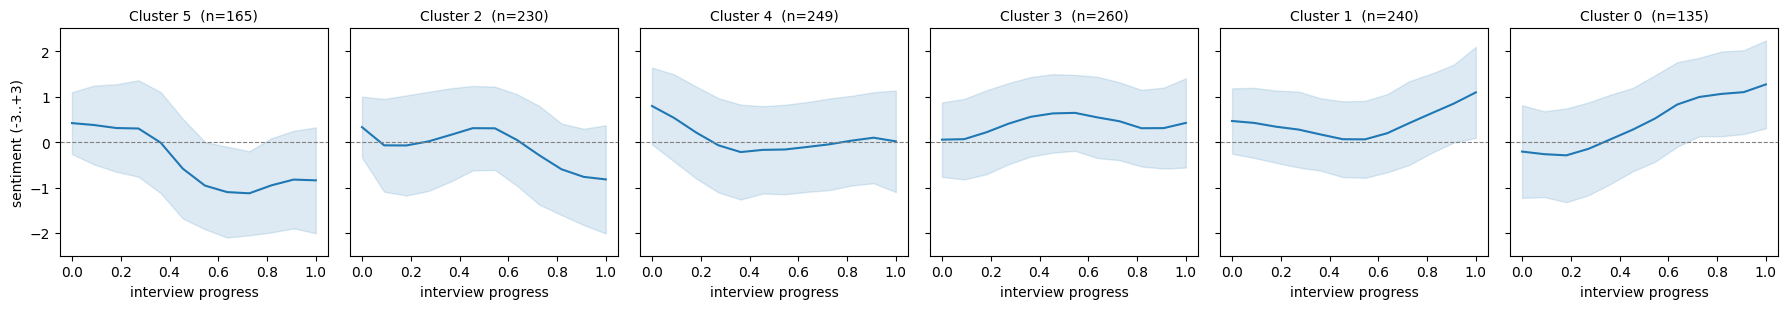

Cluster 5: positive start (+0.3) -> negative end (-0.9); dips mid-interview, then recovers; over-represented emotion: disgust
Cluster 2: neutral start (+0.0) -> negative end (-0.6); rises to a peak mid-interview, then eases; over-represented emotion: disgust
Cluster 4: positive start (+0.4) -> neutral end (+0.0); dips mid-interview, then recovers; over-represented emotion: happy
Cluster 3: neutral start (+0.2) -> positive end (+0.4); rises to a peak mid-interview, then eases; over-represented emotion: fear
Cluster 1: positive start (+0.4) -> positive end (+0.7); dips mid-interview, then recovers; over-represented emotion: happy
Cluster 0: neutral start (-0.2) -> positive end (+1.1); warms up over time; over-represented emotion: happy


In [9]:
def level_word(v):
    return 'positive' if v > 0.33 else 'negative' if v < -0.33 else 'neutral'

def describe(arc, emo_lift):
    s0, s1 = arc[:L // 3].mean(), arc[-L // 3:].mean()
    mid = arc[L // 3:2 * L // 3].mean()
    d = s1 - s0
    curv = mid - (s0 + s1) / 2
    vol = np.abs(np.diff(arc)).mean()
    if curv > 0.3:
        shp = 'rises to a peak mid-interview, then eases'
    elif curv < -0.3:
        shp = 'dips mid-interview, then recovers'
    elif d > 0.3:
        shp = 'warms up over time'
    elif d < -0.3:
        shp = 'cools off over time'
    else:
        shp = 'stays fairly flat'
    swing = ' with big swings' if vol > 0.7 else ''
    distinctive = EMOTIONS[int(np.argmax(emo_lift))]
    return (f'{level_word(s0)} start ({s0:+.1f}) -> {level_word(s1)} end ({s1:+.1f}); '
            f'{shp}{swing}; over-represented emotion: {distinctive}')

descriptions = {}
order = sorted(range(CHOSEN_K), key=lambda c: delta[labels == c].mean())
fig, axes = plt.subplots(1, CHOSEN_K, figsize=(3.0 * CHOSEN_K, 3.2), sharey=True)
if CHOSEN_K == 1:
    axes = [axes]
for ax, c in zip(axes, order):
    members = arcs[labels == c]
    mean_arc = members.mean(axis=0)
    std_arc = members.std(axis=0)
    emo_lift = emotion_means[labels == c].mean(axis=0) - emotion_base
    descriptions[c] = describe(mean_arc, emo_lift)
    ax.plot(grid, mean_arc, color='tab:blue')
    ax.fill_between(grid, mean_arc - std_arc, mean_arc + std_arc, alpha=0.15, color='tab:blue')
    ax.axhline(0, color='grey', lw=0.8, ls='--')
    ax.set_title(f'Cluster {c}  (n={int((labels==c).sum())})', fontsize=10)
    ax.set_xlabel('interview progress')
    ax.set_ylim(-2.5, 2.5)
axes[0].set_ylabel('sentiment (-3..+3)')
plt.tight_layout(); plt.show()
for c in order:
    print(f'Cluster {c}: {descriptions[c]}')

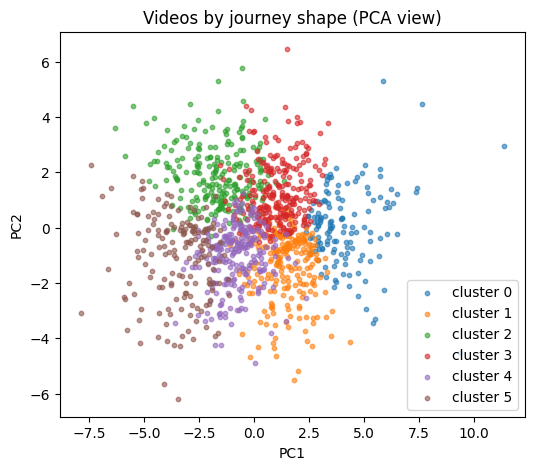

In [10]:
coords = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)
plt.figure(figsize=(6, 5))
for c in range(CHOSEN_K):
    m = labels == c
    plt.scatter(coords[m, 0], coords[m, 1], s=10, alpha=0.6, label=f'cluster {c}')
plt.legend(); plt.title('Videos by journey shape (PCA view)'); plt.xlabel('PC1'); plt.ylabel('PC2')
plt.show()

## 8. Example videos per cluster

Videos closest to each cluster center are the clearest examples. Read the sentiment sequence and transcript to confirm the shape.

In [11]:
centers = km.cluster_centers_
for c in order:
    idx = np.where(labels == c)[0]
    dd = np.linalg.norm(X[idx] - centers[c], axis=1)
    nearest = idx[np.argsort(dd)[:3]]
    print('=' * 92)
    print(f'CLUSTER {c}  (n={len(idx)}): {descriptions[c]}')
    print('=' * 92)
    for i in nearest:
        v = vids[i]
        seq = np.round(journeys[v]['sentiment'], 2)
        print(f'\n  video {v} | {journeys[v]["n"]} utterances | sentiment: {list(seq)}')
        for k, t in enumerate(journeys[v]['transcript']):
            print(f'    [{seq[k]:+.2f}] {t[:105]}')
    print()

CLUSTER 5  (n=165): positive start (+0.3) -> negative end (-0.9); dips mid-interview, then recovers; over-represented emotion: disgust

  video nsLACXjD4KU | 4 utterances | sentiment: [np.float64(0.0), np.float64(-0.67), np.float64(-2.33), np.float64(-0.67)]
    [+0.00] i felt out of place before i could turn these experiences into funny stories
    [-0.67] studies show that for anyone being the victim of a can lead to immediate distress worry anger and confusi
    [-2.33] but for people of color who experience daily racial they can have long term mental effects often in the f
    [-0.67] subtle racism takes a physical toll on our bodies

  video _xjBqNfiEY4 | 6 utterances | sentiment: [np.float64(2.0), np.float64(2.0), np.float64(2.0), np.float64(0.0), np.float64(0.67), np.float64(0.67)]
    [+2.00] university of illinois candidates are very prepared and have a great pre dental club and that is somethin
    [+2.00] of not only the pre dental club but all the other organizations you ha

## 9. Export results

In [12]:
summary_rows = []
for c in range(CHOSEN_K):
    mean_arc = arcs[labels == c].mean(axis=0)
    emo_lift = emotion_means[labels == c].mean(axis=0) - emotion_base
    summary_rows.append({
        'cluster': c,
        'size': int((labels == c).sum()),
        'description': descriptions[c],
        'mean_sentiment': float(mean_arc.mean()),
        'start_sentiment': float(mean_arc[:L // 3].mean()),
        'end_sentiment': float(mean_arc[-L // 3:].mean()),
        'curvature': float(mean_arc[L // 3:2 * L // 3].mean() - (mean_arc[:L // 3].mean() + mean_arc[-L // 3:].mean()) / 2),
        'over_represented_emotion': EMOTIONS[int(np.argmax(emo_lift))],
        'mean_arc': ';'.join(f'{x:.3f}' for x in mean_arc),
    })
cluster_summary = pd.DataFrame(summary_rows)
assign.to_csv(os.path.join(OUTPUT_DIR, 'cluster_assignments.csv'), index=False)
cluster_summary.to_csv(os.path.join(OUTPUT_DIR, 'cluster_summaries.csv'), index=False)
print('wrote cluster_assignments.csv and cluster_summaries.csv to', OUTPUT_DIR)
cluster_summary[['cluster','size','description']]

wrote cluster_assignments.csv and cluster_summaries.csv to /content/drive/MyDrive/Northwestern x Accenture/Dataset/CMU-MOSEI/clustering_outputs


,cluster,size,description
0,0,135,neutral start (-0.2) -> positive end (+1.1); w...
1,1,240,positive start (+0.4) -> positive end (+0.7); ...
2,2,230,neutral start (+0.0) -> negative end (-0.6); r...
3,3,260,neutral start (+0.2) -> positive end (+0.4); r...
4,4,249,positive start (+0.4) -> neutral end (+0.0); d...
5,5,165,positive start (+0.3) -> negative end (-0.9); ...


## Notes and next steps

- **What changed from v1.** v1 kept the overall sentiment level, so k-means split positive vs negative (k=2) and told us nothing about journeys. This version removes each arc's own average and clusters on the *movement*, so the clusters are trajectory shapes (rising, falling, dip-in-middle, peak-in-middle, flat).
- **Why not just trust silhouette.** On this data silhouette always prefers the fewest clusters, because the single biggest contrast is up vs down. We fix `CHOSEN_K` for interpretable archetypes instead; the sweep is shown so the choice is transparent.
- **Emotion labels.** MOSEI is dominated by 'happy', so each cluster's single most common emotion is happy and uninformative. We report the emotion most over-represented versus the dataset average instead (e.g., falling arcs over-index on disgust/anger/sad).
- **MOSEI caveat.** Sentiment is quantized (thirds) and the 6 emotions are sparse, so sentiment carries most of the shape. About a third of videos barely move.
- **Tunables.** `L`, `CHOSEN_K`, and whether to add emotion channels back into the features.
- **Hand-off.** From `cluster_summaries.csv` take the archetypes; from `cluster_assignments.csv` take the nearest-to-center videos as the 10-15 example journeys for Adolfo. Then pair one archetype with one persona for the first paired comparison.
